In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.decomposition import PCA

print("All imports completed successfully!")

All imports completed successfully!


In [27]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [28]:

df = pd.read_csv('/content/Cleaned_Dataset.csv')

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (180519, 53)


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,59405.0,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,59405.0,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,59405.0,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,59405.0,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,59405.0,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class


In [29]:

print("Column names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
display(df.isnull().sum().sort_values(ascending=False).head(10))

print("\nStatistical summary:")
display(df.describe())

Column names:
['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Delivery Status', 'Late_delivery_risk', 'Category Id', 'Category Name', 'Customer City', 'Customer Country', 'Customer Email', 'Customer Fname', 'Customer Id', 'Customer Lname', 'Customer Password', 'Customer Segment', 'Customer State', 'Customer Street', 'Customer Zipcode', 'Department Id', 'Department Name', 'Latitude', 'Longitude', 'Market', 'Order City', 'Order Country', 'Order Customer Id', 'order date (DateOrders)', 'Order Id', 'Order Item Cardprod Id', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Id', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Order Item Total', 'Order Profit Per Order', 'Order Region', 'Order State', 'Order Status', 'Order Zipcode', 'Product Card Id', 'Product Category Id', 'Product Description', 'Product Image', 'Product Name', 'Product Price', 'Product Status', 'shipping 

,0
Product Description,180519
Customer Lname,8
Days for shipping (real),0
Benefit per order,0
Days for shipment (scheduled),0
Sales per customer,0
Delivery Status,0
Category Id,0
Late_delivery_risk,0
Customer City,0



Statistical summary:


,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Late_delivery_risk,Category Id,Customer Id,Customer Zipcode,Department Id,Latitude,...,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Price,Product Status
count,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,...,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,0.0,180519.000000,180519.0
mean,3.497654,2.931847,21.974989,183.107609,0.548291,31.851451,6691.379495,35920.852021,5.443460,29.719955,...,2.127638,203.772096,183.107609,21.974989,58857.494901,692.509764,31.851451,NaN,141.232550,0.0
std,1.623722,1.374449,104.433526,120.043670,0.497664,15.640064,4162.918106,37542.209723,1.629246,9.813646,...,1.453451,132.273077,120.043670,104.433526,11919.294137,336.446807,15.640064,NaN,139.732492,0.0
min,0.000000,0.000000,-4274.979980,7.490000,0.000000,2.000000,1.000000,603.000000,2.000000,-33.937553,...,1.000000,9.990000,7.490000,-4274.979980,1040.000000,19.000000,2.000000,NaN,9.990000,0.0
25%,2.000000,2.000000,7.000000,104.379997,0.000000,18.000000,3258.500000,725.000000,4.000000,18.265432,...,1.000000,119.980003,104.379997,7.000000,59405.000000,403.000000,18.000000,NaN,50.000000,0.0
50%,3.000000,4.000000,31.520000,163.990005,1.000000,29.000000,6457.000000,19380.000000,5.000000,33.144863,...,1.000000,199.919998,163.990005,31.520000,59405.000000,627.000000,29.000000,NaN,59.990002,0.0
75%,5.000000,4.000000,64.800003,247.399994,1.000000,45.000000,9779.000000,78207.000000,7.000000,39.279617,...,3.000000,299.950012,247.399994,64.800003,59405.000000,1004.000000,45.000000,NaN,199.990005,0.0
max,6.000000,4.000000,911.799988,1939.989990,1.000000,76.000000,20757.000000,99205.000000,12.000000,48.781933,...,5.000000,1999.989990,1939.989990,911.799988,99301.000000,1363.000000,76.000000,NaN,1999.989990,0.0


In [30]:

numeric_features = [
    'Days for shipment (scheduled)',
        'Benefit per order',
            'Sales per customer',
                'Order Item Discount',
                    'Order Item Discount Rate',
                        'Order Item Product Price',
                            'Order Item Quantity',
                                'Sales',
                                    'Order Item Total',
                                        'Order Item Profit Ratio',
                                            'Product Price'
                                            ]

categorical_features = [
                                                'Type',
                                                    'Category Name',
                                                        'Customer Segment',
                                                            'Department Name',
                                                                'Market',
                                                                    'Order Region',
                                                                        'Shipping Mode'
                                                                        ]
X = df[numeric_features + categorical_features].copy()

print("Selected numerical features:", len(numeric_features))
print("Selected categorical features:", len(categorical_features))
display(X.head())

Selected numerical features: 11
Selected categorical features: 7


,Days for shipment (scheduled),Benefit per order,Sales per customer,Order Item Discount,Order Item Discount Rate,Order Item Product Price,Order Item Quantity,Sales,Order Item Total,Order Item Profit Ratio,Product Price,Type,Category Name,Customer Segment,Department Name,Market,Order Region,Shipping Mode
0,4,91.250000,314.640015,13.110000,0.04,327.75,1,327.75,314.640015,0.29,327.75,DEBIT,Sporting Goods,Consumer,Fitness,Pacific Asia,Southeast Asia,Standard Class
1,4,-249.089996,311.359985,16.389999,0.05,327.75,1,327.75,311.359985,-0.80,327.75,TRANSFER,Sporting Goods,Consumer,Fitness,Pacific Asia,South Asia,Standard Class
2,4,-247.779999,309.720001,18.030001,0.06,327.75,1,327.75,309.720001,-0.80,327.75,CASH,Sporting Goods,Consumer,Fitness,Pacific Asia,South Asia,Standard Class
3,4,22.860001,304.809998,22.940001,0.07,327.75,1,327.75,304.809998,0.08,327.75,DEBIT,Sporting Goods,Home Office,Fitness,Pacific Asia,Oceania,Standard Class
4,4,134.210007,298.250000,29.500000,0.09,327.75,1,327.75,298.250000,0.45,327.75,PAYMENT,Sporting Goods,Corporate,Fitness,Pacific Asia,Oceania,Standard Class


In [31]:

minmax = MinMaxScaler()

normalized_data = minmax.fit_transform(
    df[['Sales', 'Order Item Quantity', 'Product Price']]
    )

normalized_df = pd.DataFrame(
        normalized_data,
            columns=['Sales', 'Order Item Quantity', 'Product Price']
            )

print("Normalized data:")
display(normalized_df.head())

Normalized data:


,Sales,Order Item Quantity,Product Price
0,0.159678,0.0,0.159678
1,0.159678,0.0,0.159678
2,0.159678,0.0,0.159678
3,0.159678,0.0,0.159678
4,0.159678,0.0,0.159678


In [32]:

from sklearn.preprocessing import MinMaxScaler, StandardScaler

In [33]:

scaler = StandardScaler()

scaled_data = scaler.fit_transform(
    df[['Sales', 'Order Item Quantity', 'Product Price']]
    )
scaled_df = pd.DataFrame(
        scaled_data,
            columns=['Sales', 'Order Item Quantity', 'Product Price']
            )

print("Standardized data:")
display(scaled_df.head())

print("\nMeans after scaling:")
print(scaled_df.mean().round(2))

Standardized data:


,Sales,Order Item Quantity,Product Price
0,0.93729,-0.775836,1.334822
1,0.93729,-0.775836,1.334822
2,0.93729,-0.775836,1.334822
3,0.93729,-0.775836,1.334822
4,0.93729,-0.775836,1.334822



Means after scaling:
Sales                  0.0
Order Item Quantity    0.0
Product Price         -0.0
dtype: float64


In [34]:

sample = pd.DataFrame({
    'Shipping Mode': [
            'Standard Class',
                    'First Class',
                            'Same Day'
                                ]
                                })

encoder = OneHotEncoder(
    sparse_output=False,
    handle_unknown='ignore'
                                        )

encoded_data = encoder.fit_transform(sample[['Shipping Mode']])

encoded_df = pd.DataFrame(
    encoded_data,
    columns=encoder.get_feature_names_out(['Shipping Mode'])
                                                )

display(encoded_df)

,Shipping Mode_First Class,Shipping Mode_Same Day,Shipping Mode_Standard Class
0,0.0,0.0,1.0
1,1.0,0.0,0.0
2,0.0,1.0,0.0


In [35]:
from sklearn.preprocessing import OneHotEncoder

In [36]:

print("Skewness of numerical features:")

display(
    X[numeric_features]
        .skew()
            .sort_values(ascending=False)
            )

Skewness of numerical features:


,0
Order Item Product Price,3.191020
Product Price,3.191020
Order Item Discount,3.039796
Sales per customer,2.888446
Order Item Total,2.888446
Sales,2.884249
Order Item Quantity,0.880252
Order Item Discount Rate,0.340928
Days for shipment (scheduled),-0.731998
Order Item Profit Ratio,-2.893531


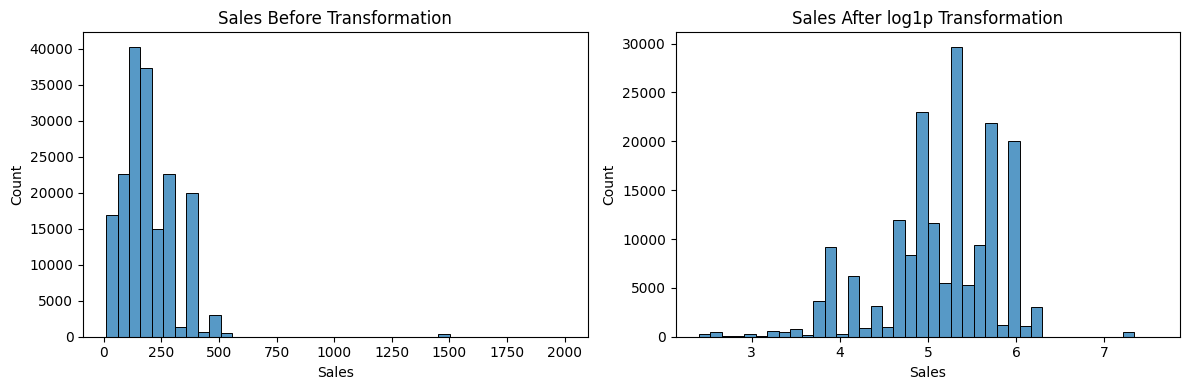

Original skewness: 2.884
Transformed skewness: -0.679


In [37]:

sales_log = np.log1p(df['Sales'])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df['Sales'], bins=40, ax=axes[0])
axes[0].set_title('Sales Before Transformation')

sns.histplot(sales_log, bins=40, ax=axes[1])
axes[1].set_title('Sales After log1p Transformation')

plt.tight_layout()
plt.show()

print("Original skewness:", round(df['Sales'].skew(), 3))
print("Transformed skewness:", round(sales_log.skew(), 3))

In [39]:

target = 'Late_delivery_risk'

y = df[target].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
        test_size=0.20,
            random_state=42,
                stratify=y
                )

numeric_pipeline = Pipeline([
                    ('imputer', SimpleImputer(strategy='median')),
                        ('scaler', StandardScaler())
                        ])

categorical_pipeline = Pipeline([
                            ('imputer', SimpleImputer(strategy='most_frequent')),
                                ('encoder', OneHotEncoder(
                                        handle_unknown='ignore',
                                                sparse_output=False
                                                    ))
                                                    ])

preprocessor = ColumnTransformer([
                                                        ('numeric', numeric_pipeline, numeric_features),
                                                            ('categorical', categorical_pipeline, categorical_features)
                                                            ])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Original training shape:", X_train.shape)
print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)
print("Preprocessing completed successfully!")

Original training shape: (144415, 18)
Processed training shape: (144415, 111)
Processed testing shape: (36104, 111)
Preprocessing completed successfully!


In [41]:

feature_names = preprocessor.get_feature_names_out()

processed_df = pd.DataFrame(
    X_train_processed[:10],
        columns=feature_names
        )

display(processed_df)

,numeric__Days for shipment (scheduled),numeric__Benefit per order,numeric__Sales per customer,numeric__Order Item Discount,numeric__Order Item Discount Rate,numeric__Order Item Product Price,numeric__Order Item Quantity,numeric__Sales,numeric__Order Item Total,numeric__Order Item Profit Ratio,...,categorical__Order Region_Southern Europe,categorical__Order Region_US Center,categorical__Order Region_West Africa,categorical__Order Region_West Asia,categorical__Order Region_West of USA,categorical__Order Region_Western Europe,categorical__Shipping Mode_First Class,categorical__Shipping Mode_Same Day,categorical__Shipping Mode_Second Class,categorical__Shipping Mode_Standard Class
0,0.776545,0.014189,-1.111163,-0.945865,-1.442081,-0.653171,-0.776755,-1.164653,-1.111163,0.748011,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
1,0.776545,0.127949,-0.714539,0.541238,2.100707,-0.079506,-0.776755,-0.558600,-0.714539,0.512418,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,-1.407696,0.202577,-0.727150,0.152303,1.392150,-0.581525,-0.088780,-0.634442,-0.727150,0.705176,...,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0
3,-0.679616,0.535822,-0.142444,0.609873,0.967015,0.422513,-0.776755,-0.028237,-0.142444,0.748011,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,-0.679616,1.454038,1.377491,1.433499,0.400169,1.856782,-0.776755,1.487011,1.377491,0.812263,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
5,-0.679616,1.405816,1.410898,1.250471,0.258457,1.856782,-0.776755,1.487011,1.410898,0.769428,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
6,-0.679616,0.330881,-0.251184,0.289574,0.683592,-0.581525,0.599196,-0.179921,-0.251184,0.533836,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
7,-0.679616,0.819409,0.901441,-0.534052,-1.016946,1.139612,-0.776755,0.729349,0.901441,0.533836,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
8,0.776545,0.564334,-0.025520,-0.030725,-0.024966,0.422513,-0.776755,-0.028237,-0.025520,0.705176,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
9,0.776545,0.223148,-0.739845,-0.694201,-0.591812,-0.653314,-0.088780,-0.786126,-0.739845,0.769428,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


In [42]:

processed_df.to_csv(
    'Week6_Processed_Sample.csv',
        index=False
        )

print("Processed sample saved successfully!")

Processed sample saved successfully!
